# Parte Específica — Análise Exploratória (Spaceship Titanic)

Dataset: [Spaceship Titanic](https://www.kaggle.com/competitions/spaceship-titanic/data), arquivo `data/parte_especifica/spaceship_train.csv`: 8.693 passageiros, 14 colunas.

Problema: **classificação** (variável alvo `Transported`).

O dashboard e este notebook leem o CSV local indicado acima. Se ele não estiver disponível, baixe o ZIP da competição e rode `python -m src.parte_especifica.preparar_dados <spaceship-titanic.zip>`.

**Pergunta de pesquisa:** Como o estado de criogenia e o planeta de origem se relacionam com a probabilidade de transporte dos passageiros?

**Público-alvo:** Estudantes e profissionais que estudam análise exploratória e comunicação de dados, interessados em como condições de viagem e origem se associam a um desfecho binário.

In [1]:
# [IA] Claude – configuração do notebook e imports
import sys
from pathlib import Path

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.parte_especifica import dados as dd

OUT = RAIZ / "out" / "parte_especifica" / "eda"
OUT.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 50)

def salvar(fig, nome):
    fig.savefig(OUT / nome, dpi=150, bbox_inches="tight")

bruto = dd.carregar_bruto()
df = dd.adicionar_derivadas(bruto)
GASTOS = dd.GASTOS
print(bruto.shape)

(8693, 14)


## 1. Estrutural

### Dicionário das variáveis

| Coluna | Significado | Tipo |
|---|---|---|
| PassengerId | Identificador `gggg_pp` (grupo + número no grupo) | identificador |
| HomePlanet | Planeta de origem | qualitativa nominal |
| CryoSleep | Em animação suspensa durante a viagem | qualitativa binária |
| Cabin | Cabine `deck/num/side` (P = bombordo, S = estibordo) | texto estruturado |
| Destination | Planeta de destino | qualitativa nominal |
| Age | Idade (anos) | quantitativa contínua |
| VIP | Pagou serviço VIP | qualitativa binária |
| RoomService, FoodCourt, ShoppingMall, Spa, VRDeck | Valor gasto em cada serviço de bordo | quantitativas contínuas |
| Name | Nome do passageiro | texto |
| Transported | Foi transportado para outra dimensão — **alvo** | qualitativa binária |

### Variáveis derivadas (`src/parte_especifica/dados.py`)

| Coluna | Como é obtida |
|---|---|
| Group, GroupSize, Solo | Grupo do `PassengerId`, tamanho do grupo, viaja sozinho |
| Deck, CabinNum, Side | Partes de `Cabin` |
| TotalSpend, AnySpend | Soma dos 5 gastos; gastou algo |
| AgeGroup | Faixa etária |
| Falt_*, N_faltantes | Indicadores de valor ausente no dado original |

In [2]:
# [IA] Claude – dimensões, tipos e valores únicos
pd.DataFrame({
    "dtype": bruto.dtypes.astype(str),
    "valores_unicos": bruto.nunique(),
    "faltantes": bruto.isna().sum(),
    "% faltantes": (bruto.isna().mean() * 100).round(2),
})

,dtype,valores_unicos,faltantes,% faltantes
PassengerId,str,8693,0,0.00
HomePlanet,str,3,201,2.31
CryoSleep,object,2,217,2.50
Cabin,str,6560,199,2.29
Destination,str,3,182,2.09
Age,float64,80,179,2.06
VIP,object,2,203,2.34
RoomService,float64,1273,181,2.08
FoodCourt,float64,1507,183,2.11
ShoppingMall,float64,1115,208,2.39


In [3]:
# [IA] Claude – checagens de consistência
tem_gasto = df[GASTOS].fillna(0).sum(axis=1) > 0
print("Linhas duplicadas:", bruto.duplicated().sum())
print("PassengerId duplicados:", bruto["PassengerId"].duplicated().sum())
print("Nomes repetidos (linhas):", bruto["Name"].dropna().duplicated(keep=False).sum())
print("CryoSleep = True com gasto > 0:", (df["CryoSleep"].eq(True) & tem_gasto).sum())
print("Age <= 12 com gasto > 0:", (df["Age"].le(12) & tem_gasto).sum())
print("Age = 0:", (df["Age"] == 0).sum())
print("Grupos com mais de um HomePlanet:", (df.groupby("Group")["HomePlanet"].nunique() > 1).sum())
print("Grupos:", df["Group"].nunique(), "| passageiros sozinhos:", (df["GroupSize"] == 1).sum())
print("Passageiros com gasto total = 0:", (df["TotalSpend"] == 0).sum())

Linhas duplicadas: 0
PassengerId duplicados: 0
Nomes repetidos (linhas): 40
CryoSleep = True com gasto > 0: 0
Age <= 12 com gasto > 0: 0
Age = 0: 178
Grupos com mais de um HomePlanet: 0
Grupos: 6217 | passageiros sozinhos: 4805
Passageiros com gasto total = 0: 3653


> ✍️ **Análise do grupo:** a base tem 8.693 passageiros e 14 colunas, sem nenhuma linha duplicada. Temos poucas quantitativas (idade e os cinco gastos), algumas categóricas (planeta, destino, criogenia, VIP) e três colunas de texto que escondem informação útil: do `PassengerId` tiramos o grupo de viagem e da `Cabin` tiramos deck, número e lado.

Algumas coisas pareciam estranhas, mas fazem sentido:
- **178 pessoas com idade 0:** ninguém gastou nada e 96% viajam em grupo. São bebês com a família, não erro.
- **40 nomes repetidos:** nunca estão no mesmo grupo, então são só homônimos.
- **42% com gasto zero:** bate com as regras do navio. Ninguém em criogenia gastou, e nenhuma criança até 12 anos também.

## 2. Dados faltantes e mecanismo de ausência

Para discutir o mecanismo (MCAR, MAR ou MNAR), compara-se a taxa de ausência entre grupos e com o alvo.

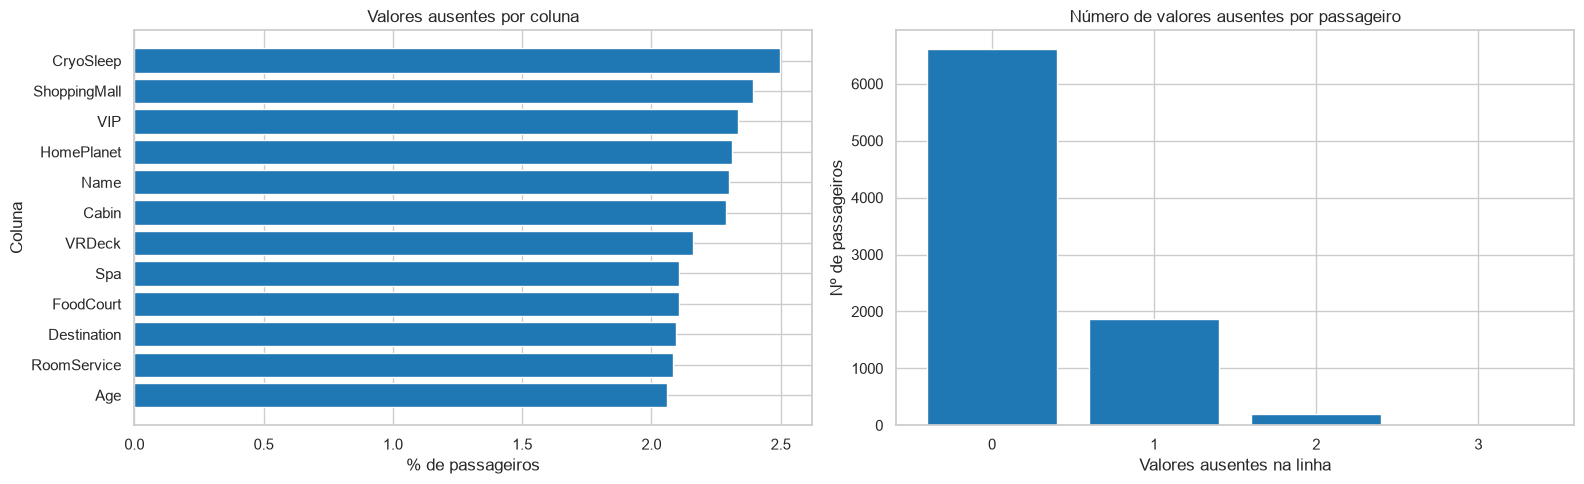

Passageiros com ao menos um faltante: 2087 (24.0%)


In [4]:
# [IA] Claude – quantos valores faltam por linha e por coluna
cols = dd.COLUNAS_COM_FALTANTES
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
taxa = bruto[cols].isna().mean().sort_values() * 100
axes[0].barh(taxa.index, taxa.values, color="tab:blue")
axes[0].set_title("Valores ausentes por coluna")
axes[0].set_xlabel("% de passageiros")
axes[0].set_ylabel("Coluna")
contagem = df["N_faltantes"].value_counts().sort_index()
axes[1].bar(contagem.index.astype(str), contagem.values, color="tab:blue")
axes[1].set_title("Número de valores ausentes por passageiro")
axes[1].set_xlabel("Valores ausentes na linha")
axes[1].set_ylabel("Nº de passageiros")
fig.tight_layout()
salvar(fig, "faltantes_resumo.png")
plt.show()
print(f"Passageiros com ao menos um faltante: {(df['N_faltantes'] > 0).sum()} ({(df['N_faltantes'] > 0).mean():.1%})")

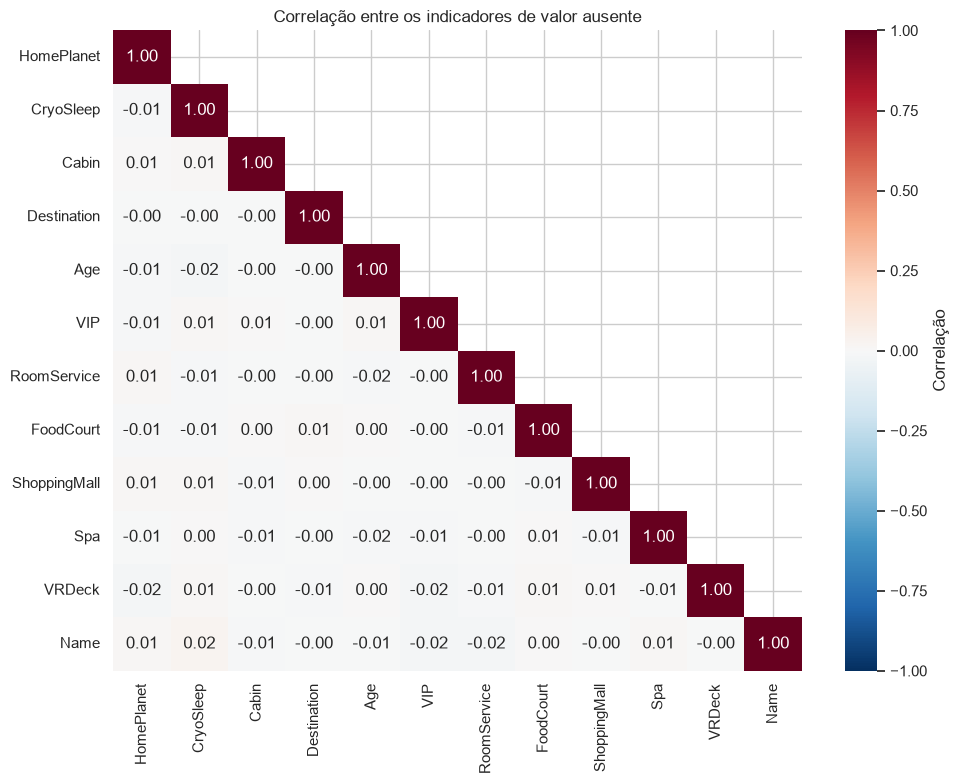

In [5]:
# [IA] Claude – correlação entre os indicadores de ausência
falt = df[[f"Falt_{c}" for c in cols]].rename(columns=lambda c: c.replace("Falt_", ""))
corr = falt.corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, cbar_kws={"label": "Correlação"}, ax=ax)
ax.set_title("Correlação entre os indicadores de valor ausente")
fig.tight_layout()
salvar(fig, "faltantes_correlacao.png")
plt.show()

In [6]:
# [IA] Claude – % de ausência por grupo observado
linhas = {}
for g in ["HomePlanet", "CryoSleep", "Destination", "VIP", "Deck", "Transported"]:
    t = df.groupby(df[g].astype(object).fillna("(ausente)").astype(str))[[f"Falt_{c}" for c in cols]].mean() * 100
    t.index = [f"{g} = {i}" for i in t.index]
    linhas[g] = t
pd.concat(linhas.values()).rename(columns=lambda c: c.replace("Falt_", "")).round(1)

,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name
HomePlanet = (ausente),100.0,1.0,3.0,2.0,1.0,1.5,3.0,1.0,3.5,1.5,0.5,3.5
HomePlanet = Earth,0.0,2.5,2.1,2.2,1.9,2.5,2.2,2.1,2.4,2.2,2.4,2.3
HomePlanet = Europa,0.0,2.7,2.9,1.7,2.2,2.0,1.7,2.2,2.5,2.1,1.7,2.2
HomePlanet = Mars,0.0,2.4,2.1,2.4,2.4,2.4,2.0,2.2,2.0,2.0,2.2,2.3
CryoSleep = (ausente),0.9,100.0,3.2,1.8,0.5,3.2,0.9,1.4,3.7,2.3,3.2,4.6
CryoSleep = False,2.3,0.0,2.0,2.4,1.8,2.2,2.0,2.0,1.9,2.1,2.2,2.4
CryoSleep = True,2.5,0.0,2.8,1.6,2.7,2.5,2.2,2.3,3.2,2.1,2.0,2.0
Destination = (ausente),2.2,2.2,2.2,100.0,1.6,2.2,1.6,3.3,2.7,1.6,1.1,2.2
Destination = 55 Cancri e,1.7,2.4,2.8,0.0,1.9,2.4,1.6,2.1,2.7,2.2,2.2,2.4
Destination = PSO J318.5-22,2.0,2.4,2.3,0.0,1.8,2.8,2.6,2.0,2.3,2.0,1.5,2.1


In [7]:
# [IA] Claude – taxa de transporte entre quem tem e quem não tem cada valor
pd.DataFrame({
    c: {"presente": df.loc[df[f"Falt_{c}"] == 0, "Transported"].mean(),
        "ausente": df.loc[df[f"Falt_{c}"] == 1, "Transported"].mean(),
        "n ausentes": df[f"Falt_{c}"].sum()}
    for c in cols
}).T

,presente,ausente,n ausentes
HomePlanet,0.503,0.512,201.0
CryoSleep,0.504,0.488,217.0
Cabin,0.504,0.503,199.0
Destination,0.504,0.505,182.0
Age,0.504,0.503,179.0
VIP,0.503,0.512,203.0
RoomService,0.505,0.459,181.0
FoodCourt,0.503,0.541,183.0
ShoppingMall,0.503,0.548,208.0
Spa,0.504,0.497,183.0


> ✍️ **Análise do grupo:** cada coluna tem só uns 2% de faltantes, espalhados de forma bem uniforme. A taxa quase não muda entre planetas, destinos, decks ou entre transportados e não transportados, e um faltante não "puxa" outro (correlação máxima de 0,03). Por isso tratamos a maioria das variáveis (`Age`, `Destination`, `VIP`, `Cabin`, `Name`) como **MCAR**.

A exceção é quando dá para adivinhar o valor por outra coluna, o que caracteriza **MAR**:
- **Gastos:** quem está em criogenia ou é criança gastou 0, com certeza.
- **`CryoSleep`:** quem gastou alguma coisa não estava dormindo.
- **`HomePlanet`:** dá para pegar o planeta de alguém do mesmo grupo, porque nenhum grupo mistura planetas.

**MNAR** não tem como testar direito, mas também não vimos nenhum sinal dele.

### 2.1 Regras lógicas

Alguns faltantes podem ser deduzidos das outras colunas (ver `aplicar_regras_logicas`).

In [8]:
# [IA] Claude – quantos valores cada regra recupera
_, regras = dd.aplicar_regras_logicas(df)
pd.Series(regras, name="valores preenchidos").to_frame()

,valores preenchidos
Gastos = 0 por CryoSleep,361
Gastos = 0 por idade <= 12,45
CryoSleep = False por ter gasto,119
HomePlanet pelo grupo,90


### 2.2 Opções de imputação de `Age`

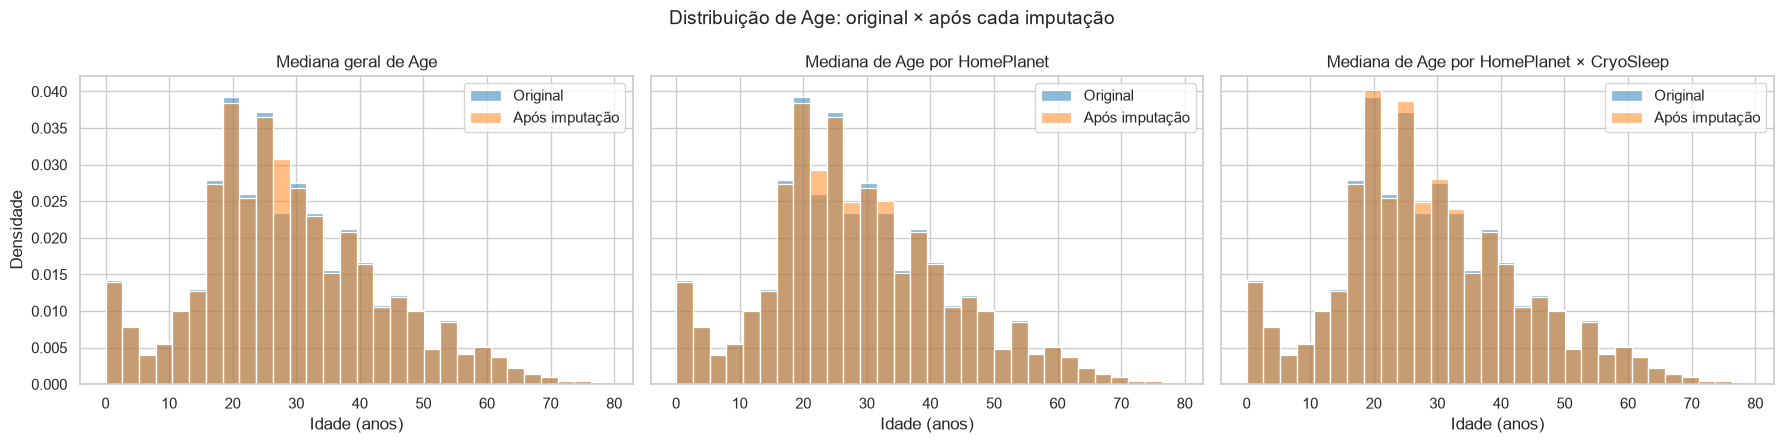

,count,mean,std,min,25%,50%,75%,max
original (sem faltantes),8514.0,28.828,14.489,0.0,19.0,27.0,38.0,79.0
Mediana geral de Age,8693.0,28.790,14.341,0.0,20.0,27.0,37.0,79.0
Mediana de Age por HomePlanet,8693.0,28.788,14.354,0.0,20.0,27.0,37.0,79.0
Mediana de Age por HomePlanet × CryoSleep,8693.0,28.780,14.356,0.0,20.0,27.0,37.0,79.0


In [9]:
# [IA] Claude – comparação das opções de imputação de Age
base, _ = dd.aplicar_regras_logicas(df)
fig, axes = plt.subplots(1, len(dd.METODOS_AGE), figsize=(18, 4.5), sharey=True)
resumo = {"original (sem faltantes)": df["Age"].describe()}
for ax, (metodo, nome) in zip(axes, dd.METODOS_AGE.items()):
    imputada = dd.imputar_age(base, metodo)
    resumo[nome] = imputada.describe()
    sns.histplot(df["Age"].dropna(), bins=30, stat="density", color="tab:blue", alpha=0.5, label="Original", ax=ax)
    sns.histplot(imputada, bins=30, stat="density", color="tab:orange", alpha=0.5, label="Após imputação", ax=ax)
    ax.set_title(nome)
    ax.set_xlabel("Idade (anos)")
    ax.set_ylabel("Densidade")
    ax.legend()
fig.suptitle("Distribuição de Age: original × após cada imputação", fontsize=14)
fig.tight_layout()
salvar(fig, "imputacao_age_opcoes.png")
plt.show()
pd.DataFrame(resumo).T

### 2.3 Tratamento adotado

**O grupo escolhe** `METODO_AGE` (`mediana_global`, `mediana_planeta`, `mediana_planeta_cryo`), `CATEGORICAS` (`desconhecido` ou `moda`) e `REGRAS` (`True` ou `False`).
O resultado é salvo em `data/parte_especifica/spaceship_tratado.csv`, lido pelo dashboard.

In [10]:
METODO_AGE = "mediana_planeta"   # o grupo deve confirmar ou trocar e justificar no relatório
CATEGORICAS = "desconhecido"     # "desconhecido" ou "moda"
REGRAS = True                    # aplica as deduções lógicas antes da imputação

tratado = dd.tratar(bruto, METODO_AGE, CATEGORICAS, REGRAS)
tratado.to_csv(dd.CAMINHO_TRATADO, index=False)
print("Faltantes após tratamento (Age, gastos, categóricas):",
      int(tratado[["Age", *GASTOS, "HomePlanet", "CryoSleep", "Destination", "VIP"]].isna().sum().sum()))
print(f"Linhas: {len(tratado)} (nenhuma removida)")

Faltantes após tratamento (Age, gastos, categóricas): 0
Linhas: 8693 (nenhuma removida)


> ✍️ **Análise do grupo:** ficamos com a configuração padrão (`mediana_planeta`, `desconhecido`, `REGRAS = True`).

- **Regras lógicas primeiro:** elas recuperam 615 valores sem chutar nada, então não tem por que não usar.
- **`Age` pela mediana do planeta:** a idade muda bastante entre planetas (Terra 23, Marte 28, Europa 33). Usamos a mediana porque ela aguenta melhor a assimetria. No fim, as três opções deram quase o mesmo resultado, já que só 2% das idades foram imputadas.
- **"Desconhecido" em vez da moda:** os 98 que continuam sem `CryoSleep` não gastaram nada e 72% foram transportados, igualzinho a quem estava em criogenia. Usar a moda ("Não") seria colocar a resposta errada.
- **Não apagamos linhas:** apagar todas as linhas com algum faltante jogaria fora 24% da base por causa de só 2% de buraco em cada coluna.

## 3. Distribucional

A partir daqui usa-se o dataset tratado.

In [11]:
# [IA] Claude – estatísticas descritivas das quantitativas
quant = ["Age", *GASTOS, "TotalSpend", "GroupSize", "CabinNum"]
desc = tratado[quant].describe().T
desc["assimetria"] = tratado[quant].skew()
desc["curtose"] = tratado[quant].kurt()
desc["% zeros"] = (tratado[quant] == 0).mean() * 100
desc

,count,mean,std,min,25%,50%,75%,max,assimetria,curtose,% zeros
Age,8693.0,28.788,14.354,0.0,20.00,27.0,37.0,79.0,0.430,0.159,2.048
RoomService,8693.0,220.009,660.519,0.0,0.00,0.0,41.0,14327.0,6.398,66.577,66.237
FoodCourt,8693.0,448.434,1595.791,0.0,0.00,0.0,61.0,29813.0,7.178,74.856,64.868
ShoppingMall,8693.0,169.572,598.007,0.0,0.00,0.0,22.0,23492.0,12.764,336.017,66.663
Spa,8693.0,304.589,1125.563,0.0,0.00,0.0,53.0,22408.0,7.716,82.921,63.350
VRDeck,8693.0,298.262,1134.126,0.0,0.00,0.0,40.0,24133.0,7.905,87.883,65.374
TotalSpend,8693.0,1440.866,2803.046,0.0,0.00,716.0,1441.0,35987.0,4.418,27.478,42.022
GroupSize,8693.0,2.036,1.596,1.0,1.00,1.0,3.0,8.0,1.889,3.167,0.000
CabinNum,8494.0,600.368,511.867,0.0,167.25,427.0,999.0,1894.0,0.718,-0.713,0.207


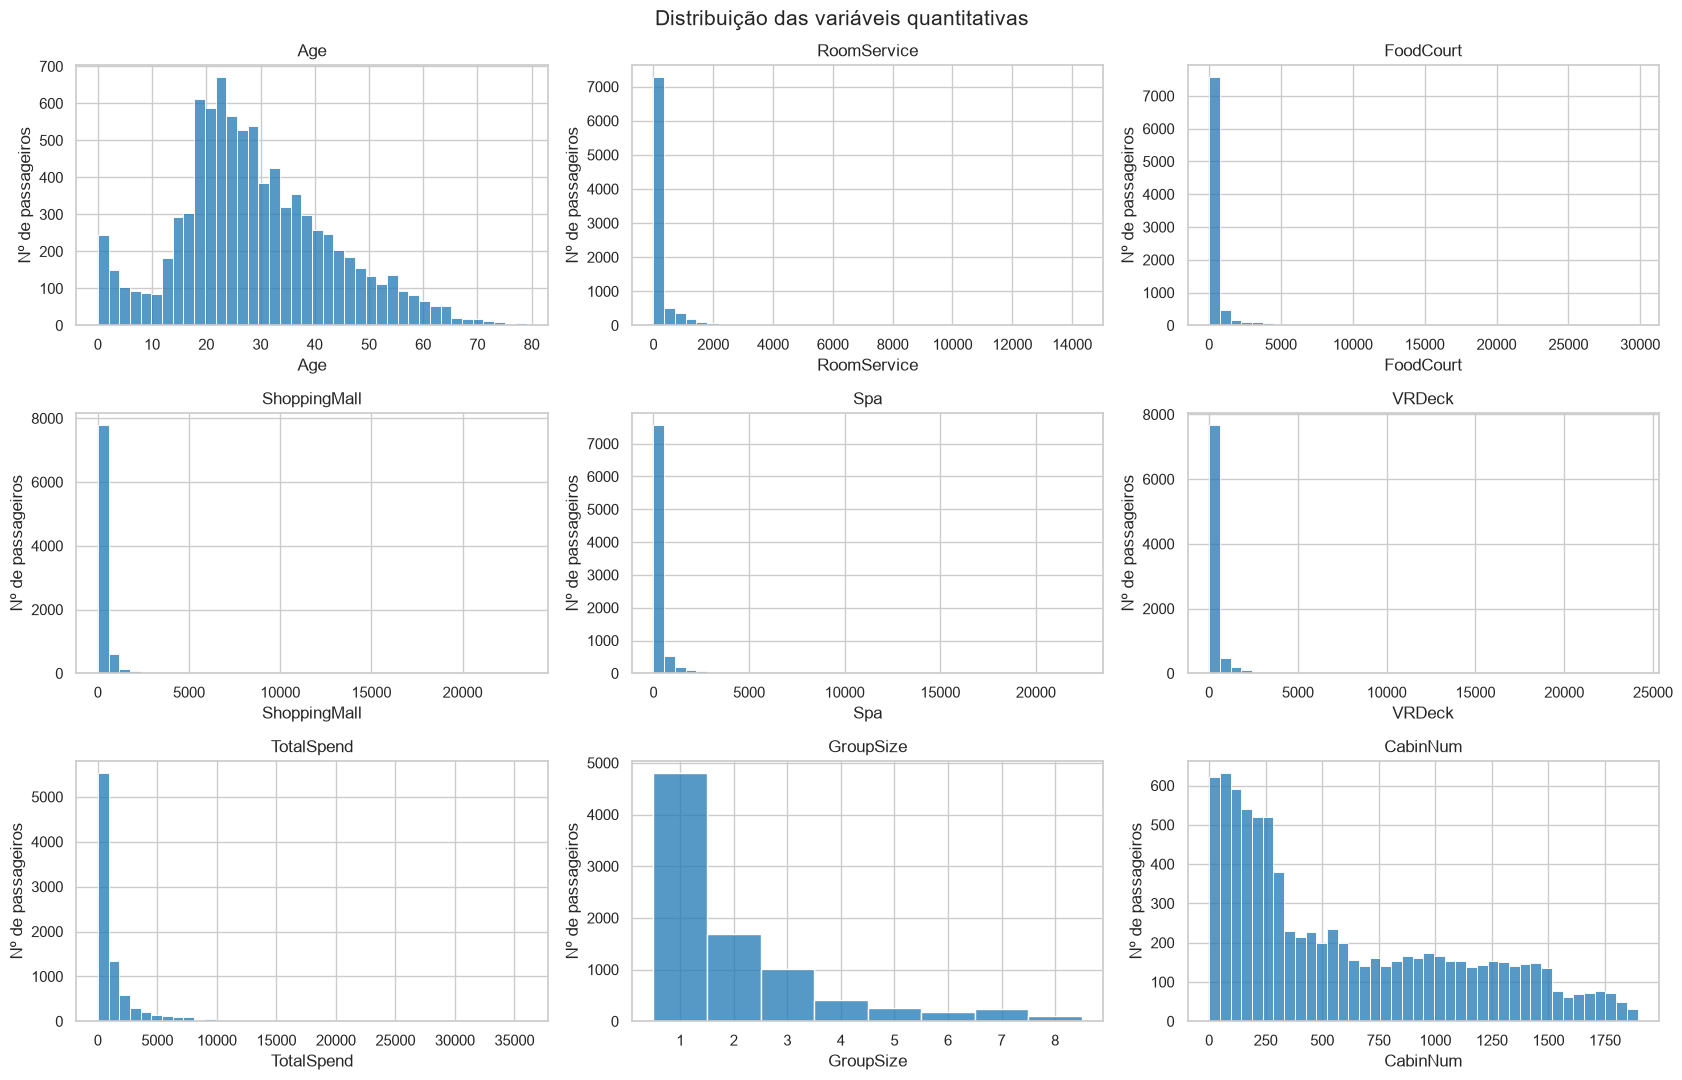

In [12]:
# [IA] Claude – histogramas das quantitativas
fig, axes = plt.subplots(3, 3, figsize=(17, 11))
for ax, col in zip(axes.flat, quant):
    discreta = tratado[col].nunique() < 15
    sns.histplot(tratado[col].dropna(), ax=ax, color="tab:blue", discrete=discreta, bins="auto" if discreta else 40)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Nº de passageiros")
fig.suptitle("Distribuição das variáveis quantitativas", fontsize=15)
fig.tight_layout()
salvar(fig, "dist_quantitativas.png")
plt.show()

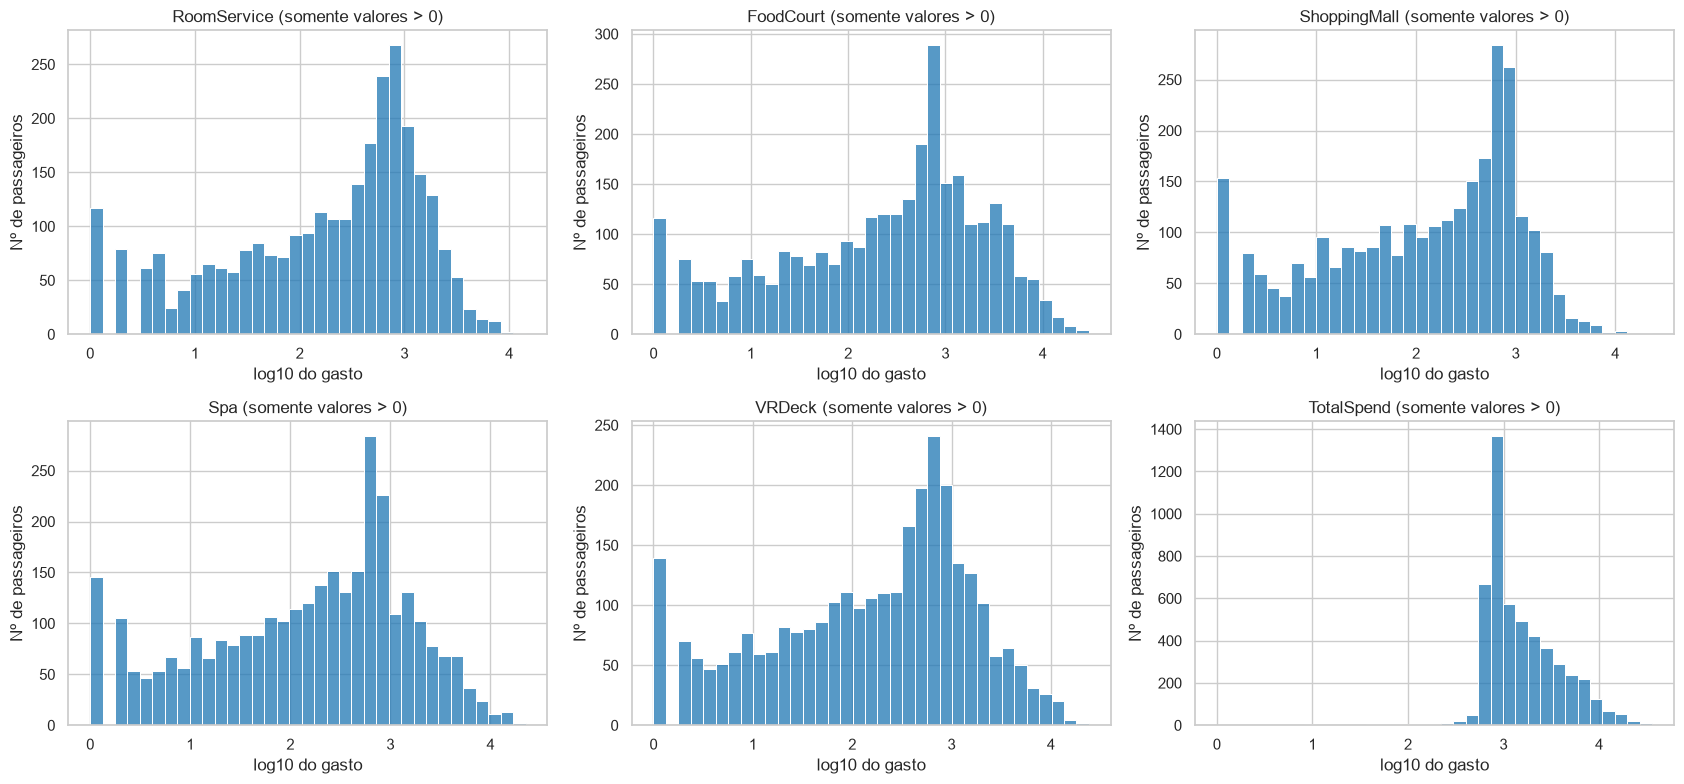

In [13]:
# [IA] Claude – gastos em escala log, só entre quem gastou
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, col in zip(axes.flat, [*GASTOS, "TotalSpend"]):
    sns.histplot(np.log10(tratado.loc[tratado[col] > 0, col]), bins=35, ax=ax, color="tab:blue")
    ax.set_title(f"{col} (somente valores > 0)")
    ax.set_xlabel("log10 do gasto")
    ax.set_ylabel("Nº de passageiros")
fig.tight_layout()
salvar(fig, "dist_gastos_log.png")
plt.show()

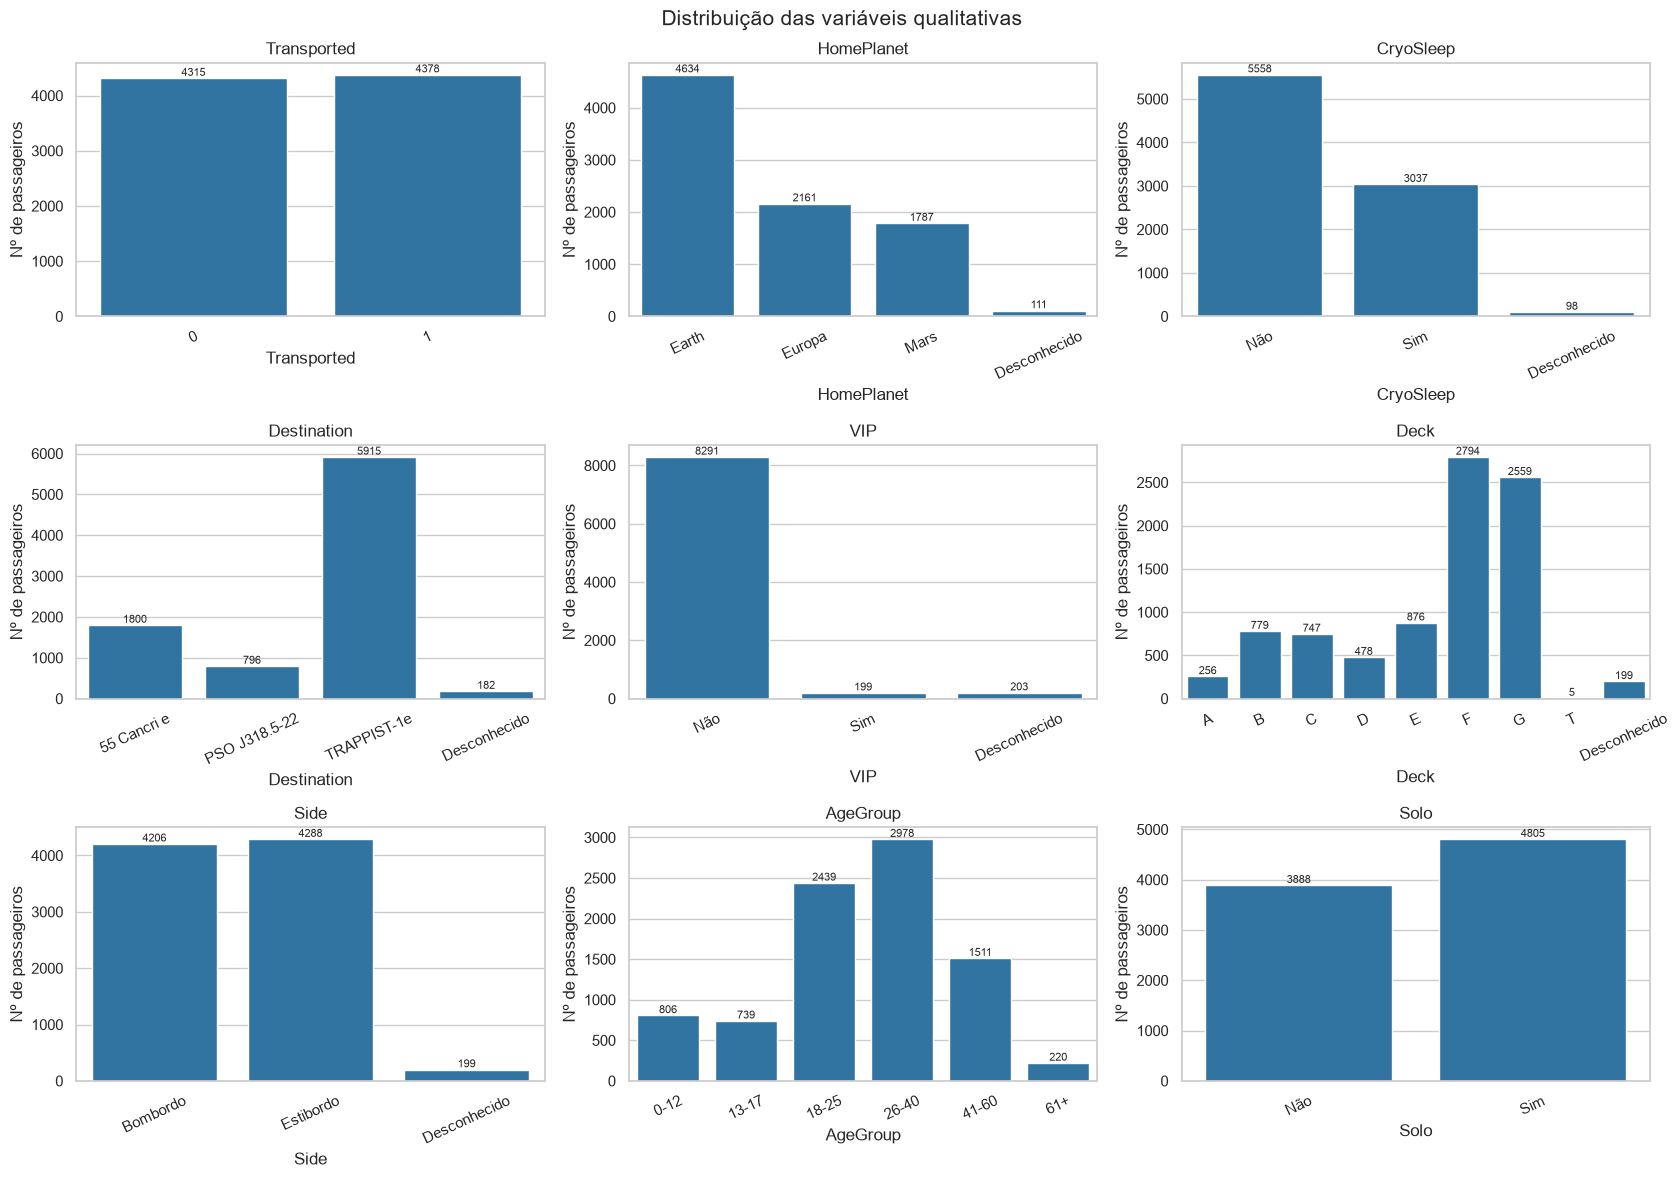

In [14]:
# [IA] Claude – frequência das qualitativas
quali = ["Transported", "HomePlanet", "CryoSleep", "Destination", "VIP", "Deck", "Side", "AgeGroup", "Solo"]
fig, axes = plt.subplots(3, 3, figsize=(17, 12))
for ax, col in zip(axes.flat, quali):
    ordem = sorted(tratado[col].unique(), key=lambda x: (x == dd.DESCONHECIDO, str(x)))
    sns.countplot(data=tratado, x=col, order=ordem, ax=ax, color="tab:blue")
    for p in ax.patches:
        ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=8)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Nº de passageiros")
    ax.tick_params(axis="x", rotation=25)
fig.suptitle("Distribuição das variáveis qualitativas", fontsize=15)
fig.tight_layout()
salvar(fig, "dist_qualitativas.png")
plt.show()

> ✍️ **Análise do grupo:** o alvo está bem equilibrado (50,4% transportados), então dá para comparar tudo com a média de uns 50%.

A idade é quase simétrica, com mediana de 27 anos e maioria de adultos jovens. Já os gastos são bem diferentes: uns 65% das pessoas gastaram 0 em cada serviço, e quem gastou tem uma cauda enorme (assimetria entre 6 e 13). Em escala log, os gastos de quem gastou ficam bem mais comportados.

Nas categóricas há bastante desequilíbrio. Mais da metade é da Terra, 68% vão para TRAPPIST-1e e só 2% são VIP. Por isso sempre olhamos o `n` junto da taxa.

## 4. Relacional

### 4.1 Taxa de transporte por variável qualitativa

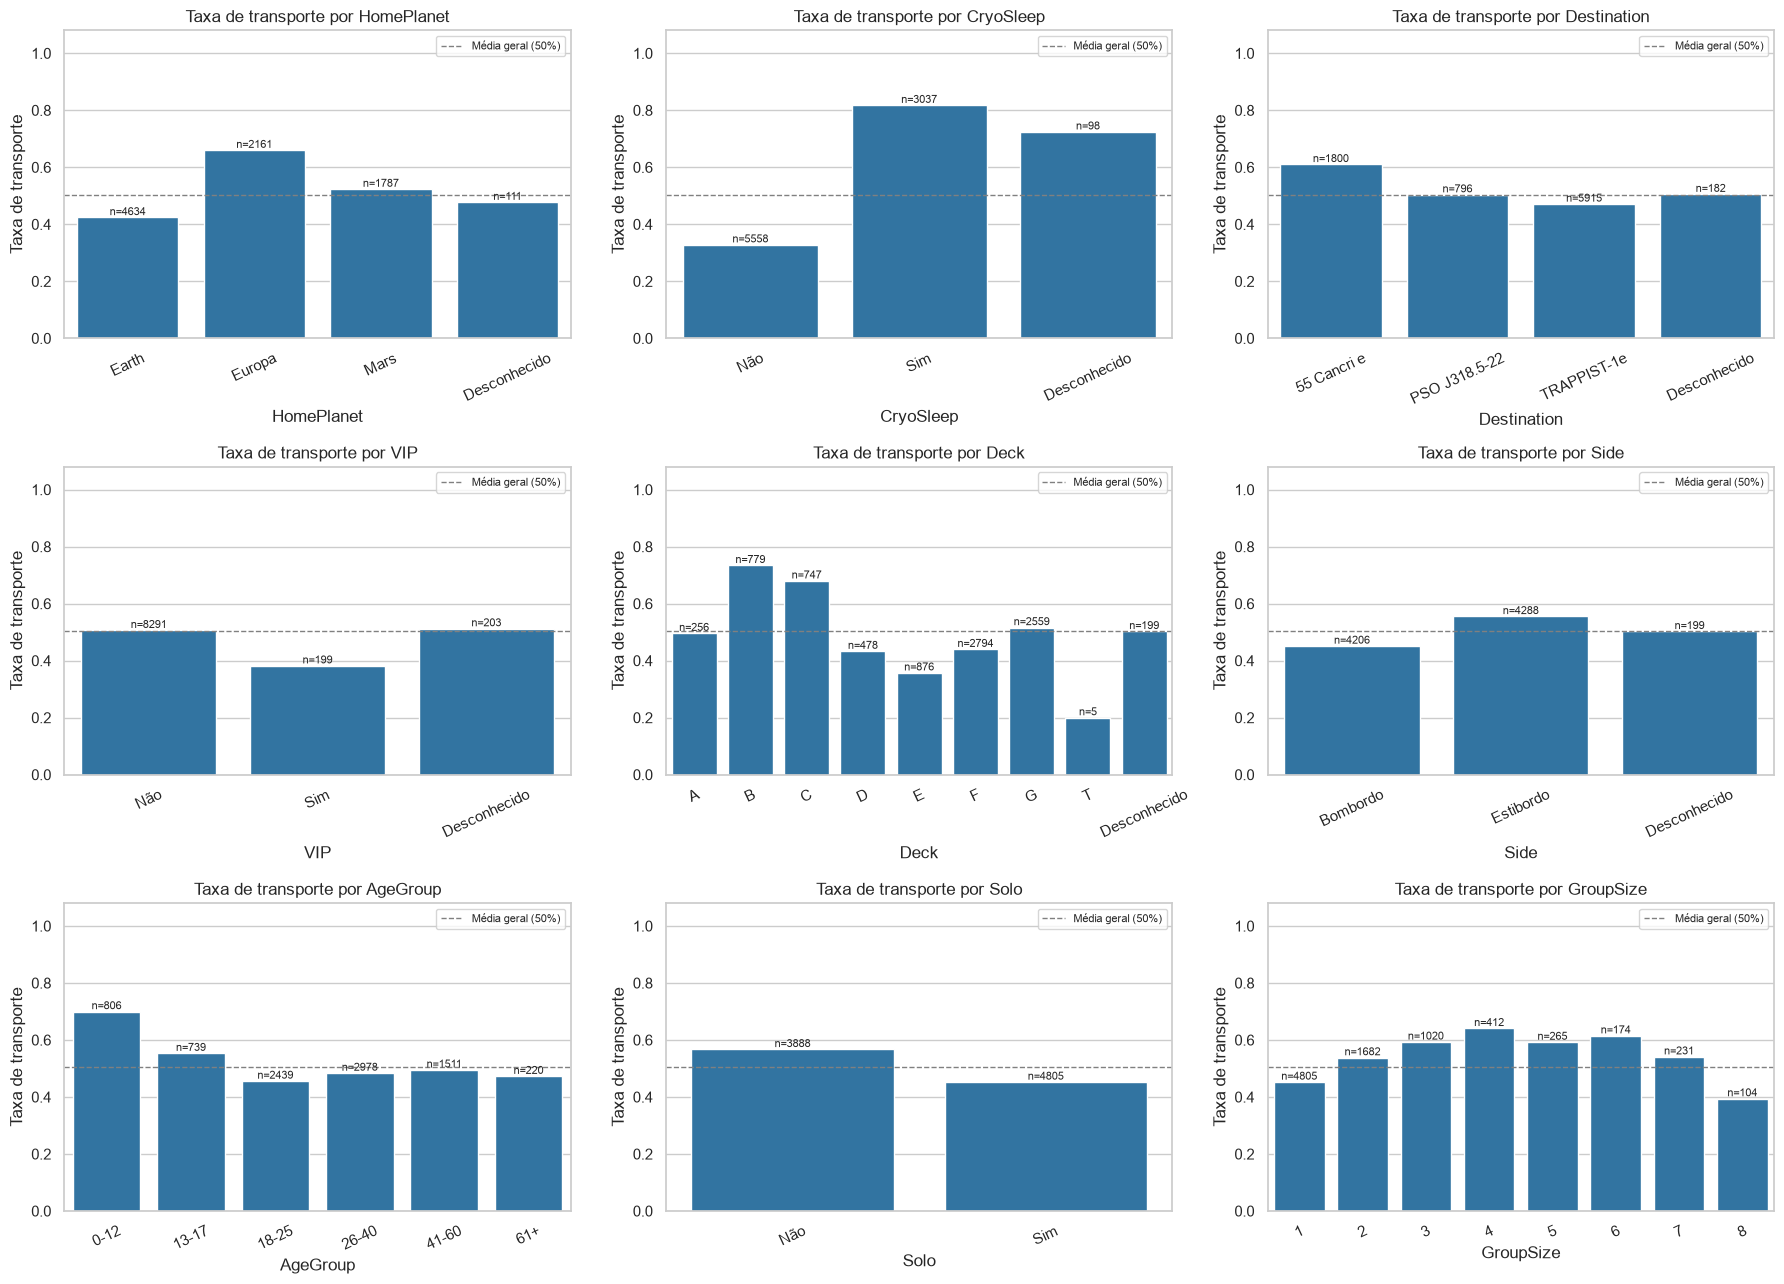

In [15]:
# [IA] Claude – taxa de transporte por categoria
taxa_geral = tratado["Transported"].mean()
cats = ["HomePlanet", "CryoSleep", "Destination", "VIP", "Deck", "Side", "AgeGroup", "Solo", "GroupSize"]
fig, axes = plt.subplots(3, 3, figsize=(18, 13))
for ax, col in zip(axes.flat, cats):
    t = tratado.groupby(col)["Transported"].agg(["mean", "size"]).reset_index()
    t[col] = t[col].astype(str)
    if col == "AgeGroup":
        t = t.set_index(col).reindex([f for f in dd.FAIXAS_IDADE if f in set(t[col])]).reset_index()
    else:
        t = t.sort_values(col, key=lambda s: s.eq(dd.DESCONHECIDO), kind="stable")
    sns.barplot(data=t, x=col, y="mean", ax=ax, color="tab:blue")
    for p, n in zip(ax.patches, t["size"]):
        ax.annotate(f"n={n}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=8)
    ax.axhline(taxa_geral, color="gray", linestyle="--", linewidth=1, label=f"Média geral ({taxa_geral:.0%})")
    ax.set_title(f"Taxa de transporte por {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Taxa de transporte")
    ax.set_ylim(0, 1.08)
    ax.tick_params(axis="x", rotation=25)
    ax.legend(fontsize=8)
fig.tight_layout()
salvar(fig, "transporte_por_categoria.png")
plt.show()

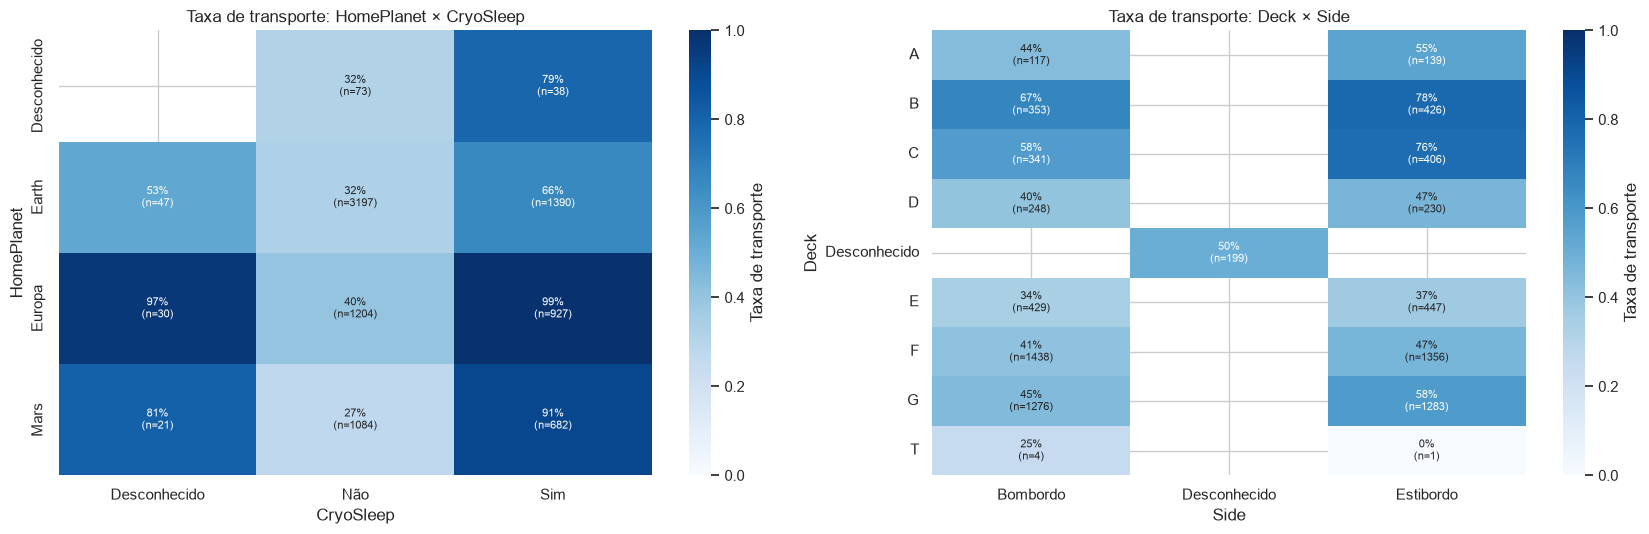

In [16]:
# [IA] Claude – taxa de transporte por combinações de duas variáveis
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
for ax, (lin, col) in zip(axes, [("HomePlanet", "CryoSleep"), ("Deck", "Side")]):
    pivo = tratado.pivot_table(index=lin, columns=col, values="Transported", aggfunc="mean")
    n = tratado.pivot_table(index=lin, columns=col, values="Transported", aggfunc="size")
    rot = pivo.copy().astype(object)
    for i in pivo.index:
        for j in pivo.columns:
            rot.loc[i, j] = "" if pd.isna(pivo.loc[i, j]) else f"{pivo.loc[i, j]:.0%}\n(n={int(n.loc[i, j])})"
    sns.heatmap(pivo, annot=rot, fmt="", annot_kws={"fontsize": 8}, cmap="Blues", vmin=0, vmax=1,
                cbar_kws={"label": "Taxa de transporte"}, ax=ax)
    ax.set_title(f"Taxa de transporte: {lin} × {col}")
fig.tight_layout()
salvar(fig, "transporte_combinacoes.png")
plt.show()

### 4.2 Quantitativas × alvo

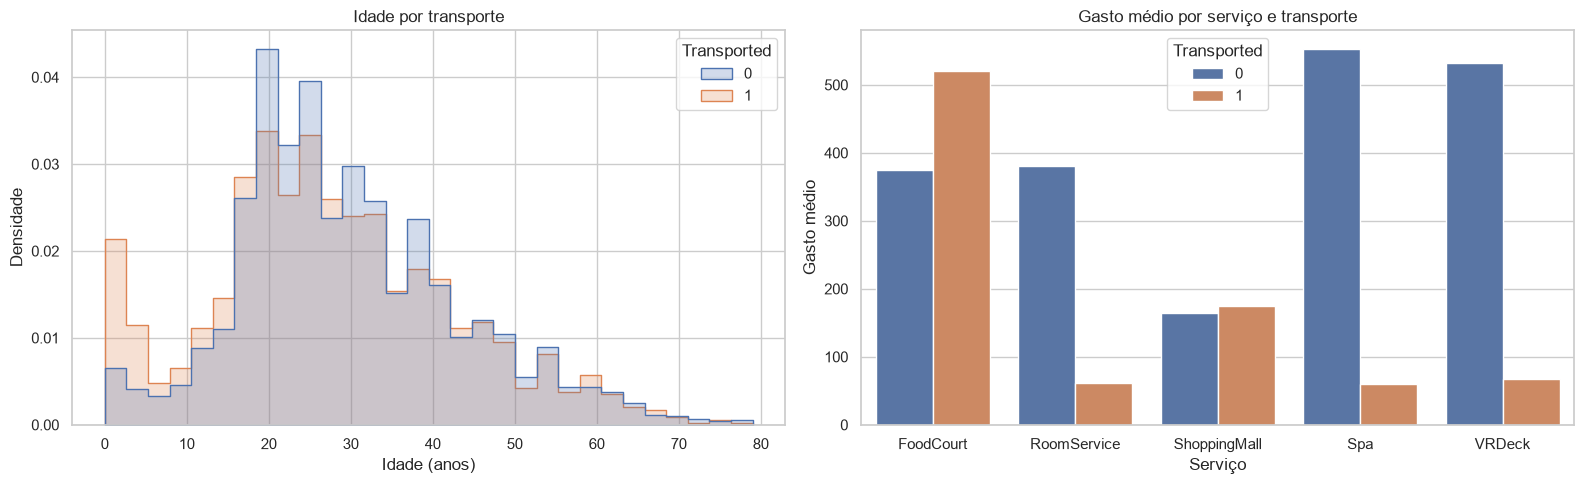

In [17]:
# [IA] Claude – idade e gastos por transporte
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(data=tratado, x="Age", hue="Transported", bins=30, element="step", stat="density",
             common_norm=False, ax=axes[0])
axes[0].set_title("Idade por transporte")
axes[0].set_xlabel("Idade (anos)")
axes[0].set_ylabel("Densidade")
longo = tratado.melt(id_vars="Transported", value_vars=GASTOS, var_name="Serviço", value_name="Gasto")
medias = longo.groupby(["Serviço", "Transported"], as_index=False)["Gasto"].mean()
sns.barplot(data=medias, x="Serviço", y="Gasto", hue="Transported", ax=axes[1])
axes[1].set_title("Gasto médio por serviço e transporte")
axes[1].set_xlabel("Serviço")
axes[1].set_ylabel("Gasto médio")
fig.tight_layout()
salvar(fig, "age_gastos_transporte.png")
plt.show()

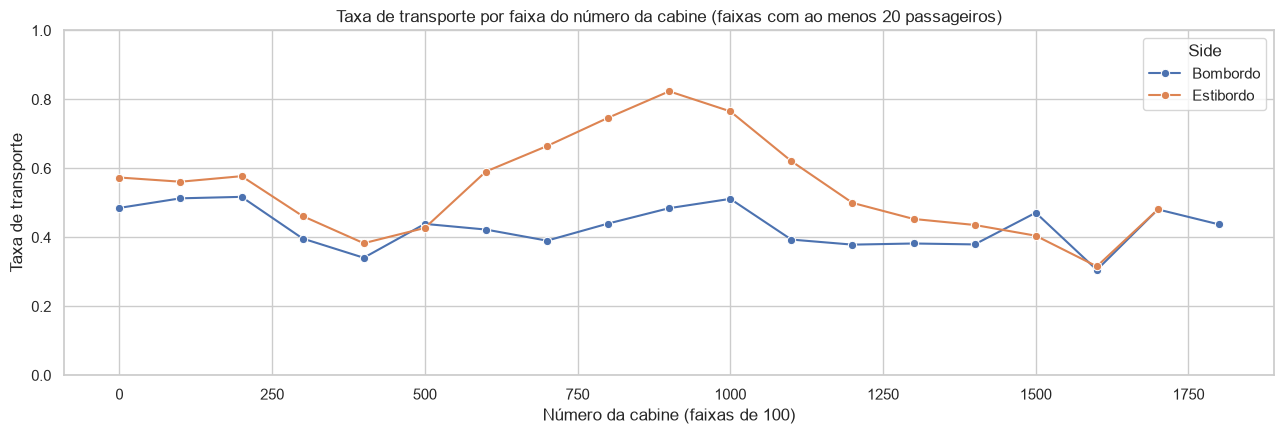

In [18]:
# [IA] Claude – taxa de transporte ao longo do número da cabine
t = tratado.dropna(subset=["CabinNum"]).assign(faixa=lambda d: (d["CabinNum"] // 100 * 100).astype(int))
t = t.groupby(["faixa", "Side"])["Transported"].agg(["mean", "size"]).reset_index().query("size >= 20")
fig, ax = plt.subplots(figsize=(13, 4.5))
sns.lineplot(data=t[t["Side"] != dd.DESCONHECIDO], x="faixa", y="mean", hue="Side", marker="o", ax=ax)
ax.set_title("Taxa de transporte por faixa do número da cabine (faixas com ao menos 20 passageiros)")
ax.set_xlabel("Número da cabine (faixas de 100)")
ax.set_ylabel("Taxa de transporte")
ax.set_ylim(0, 1)
fig.tight_layout()
salvar(fig, "transporte_cabine.png")
plt.show()

### 4.3 Matrizes de associação

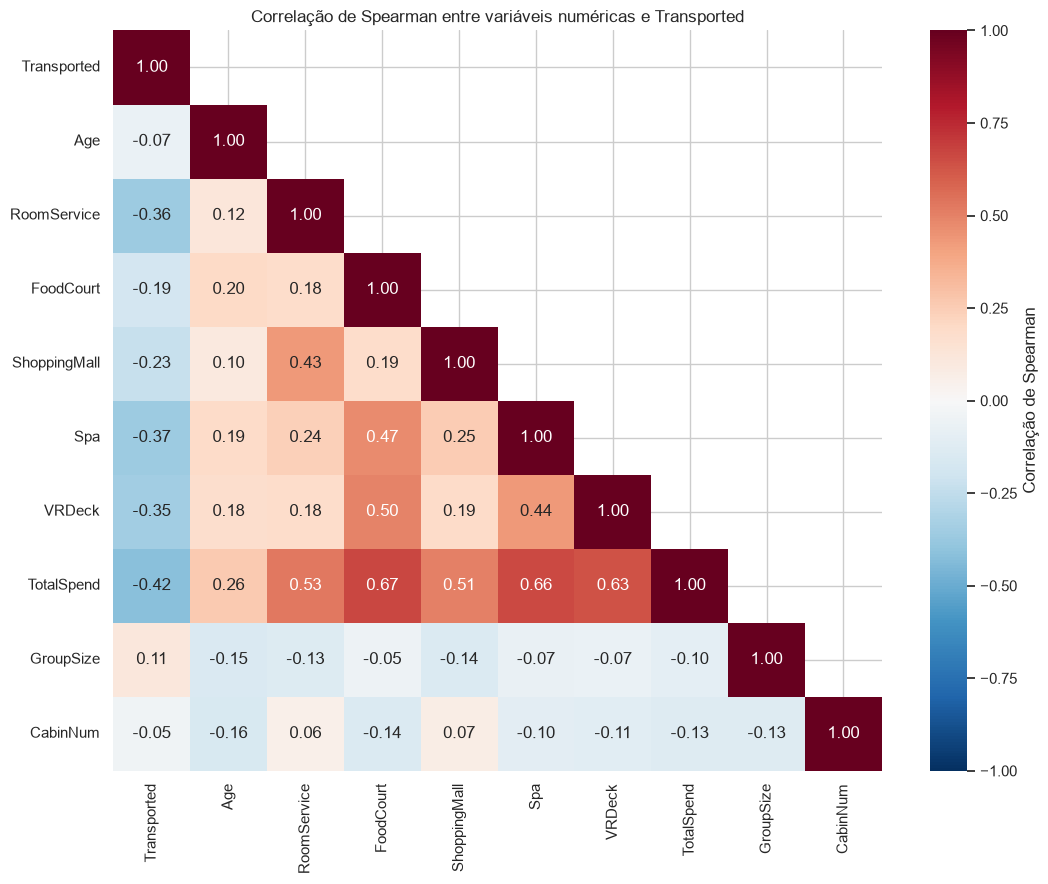

In [19]:
# [IA] Claude – correlação de Spearman
num = ["Transported", "Age", *GASTOS, "TotalSpend", "GroupSize", "CabinNum"]
corr = tratado[num].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, cbar_kws={"label": "Correlação de Spearman"}, ax=ax)
ax.set_title("Correlação de Spearman entre variáveis numéricas e Transported")
fig.tight_layout()
salvar(fig, "corr_spearman.png")
plt.show()

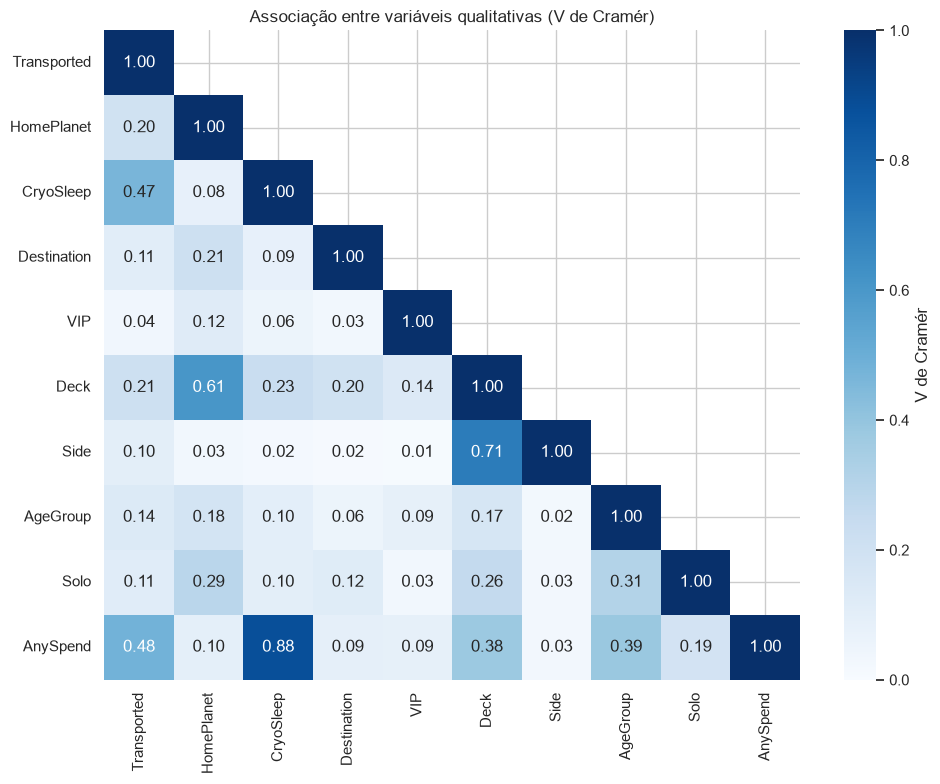

In [20]:
# [IA] Claude – V de Cramér entre qualitativas
qualis = ["Transported", "HomePlanet", "CryoSleep", "Destination", "VIP", "Deck", "Side", "AgeGroup", "Solo", "AnySpend"]
v = pd.DataFrame(index=qualis, columns=qualis, dtype=float)
for a in qualis:
    for b in qualis:
        v.loc[a, b] = dd.cramers_v(tratado[a], tratado[b])
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(v, mask=np.triu(np.ones_like(v, dtype=bool), k=1), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            cbar_kws={"label": "V de Cramér"}, ax=ax)
ax.set_title("Associação entre variáveis qualitativas (V de Cramér)")
fig.tight_layout()
salvar(fig, "cramers_v.png")
plt.show()

> ✍️ **Análise do grupo:** a criogenia é de longe o que mais pesa: 82% de quem estava dormindo foi transportado, contra 33% de quem não estava. Os gastos vão no sentido contrário (quem gasta mais é menos transportado), mas boa parte disso é a mesma história, já que quem está em criogenia não gasta.

O planeta também importa: Europa tem 66%, Marte 52% e Terra 42%. E aqui aparece a parte mais interessante para a nossa pergunta, porque os dois fatores interagem:

| | Em criogenia | Fora de criogenia |
|---|---|---|
| Europa | 99% | 40% |
| Marte | 91% | 27% |
| Terra | 66% | 32% |

A criogenia aumenta a taxa em todo planeta, mas para os terráqueos o efeito é bem menor. Outros fatores mais fracos: crianças (70%), quem viaja em grupo e o lado estibordo são um pouco mais transportados. VIP quase não faz diferença.

## 5. Outliers

Critério IQR (Q1 − 1,5·IQR, Q3 + 1,5·IQR) nas quantitativas. Nos gastos, também entre quem gastou (> 0).

In [21]:
# [IA] Claude – contagem de outliers por IQR
linhas = []
for col in ["Age", *GASTOS, "TotalSpend", "GroupSize"]:
    li, ls = dd.limites_iqr(tratado[col])
    m = (tratado[col] < li) | (tratado[col] > ls)
    linha = {"variavel": col, "lim_inf": li, "lim_sup": ls, "n_outliers": int(m.sum()), "% outliers": m.mean() * 100,
             "taxa_transporte_outliers": tratado.loc[m, "Transported"].mean(), "maximo": tratado[col].max()}
    if col in GASTOS or col == "TotalSpend":
        pos = tratado.loc[tratado[col] > 0, col]
        lp, us = dd.limites_iqr(pos)
        linha["n_outliers (só > 0)"] = int((pos > us).sum())
    linhas.append(linha)
pd.DataFrame(linhas).set_index("variavel")

,lim_inf,lim_sup,n_outliers,% outliers,taxa_transporte_outliers,maximo,n_outliers (só > 0)
variavel,,,,,,,
Age,-5.5,62.5,162,1.864,0.451,79.0,NaN
RoomService,-61.5,102.5,1906,21.926,0.205,14327.0,191.0
FoodCourt,-91.5,152.5,1916,22.041,0.422,29813.0,384.0
ShoppingMall,-33.0,55.0,1879,21.615,0.368,23492.0,176.0
Spa,-79.5,132.5,1833,21.086,0.197,22408.0,358.0
VRDeck,-60.0,100.0,1849,21.270,0.220,24133.0,325.0
TotalSpend,-2161.5,3602.5,934,10.744,0.335,35987.0,583.0
GroupSize,-2.0,6.0,335,3.854,0.496,8.0,NaN


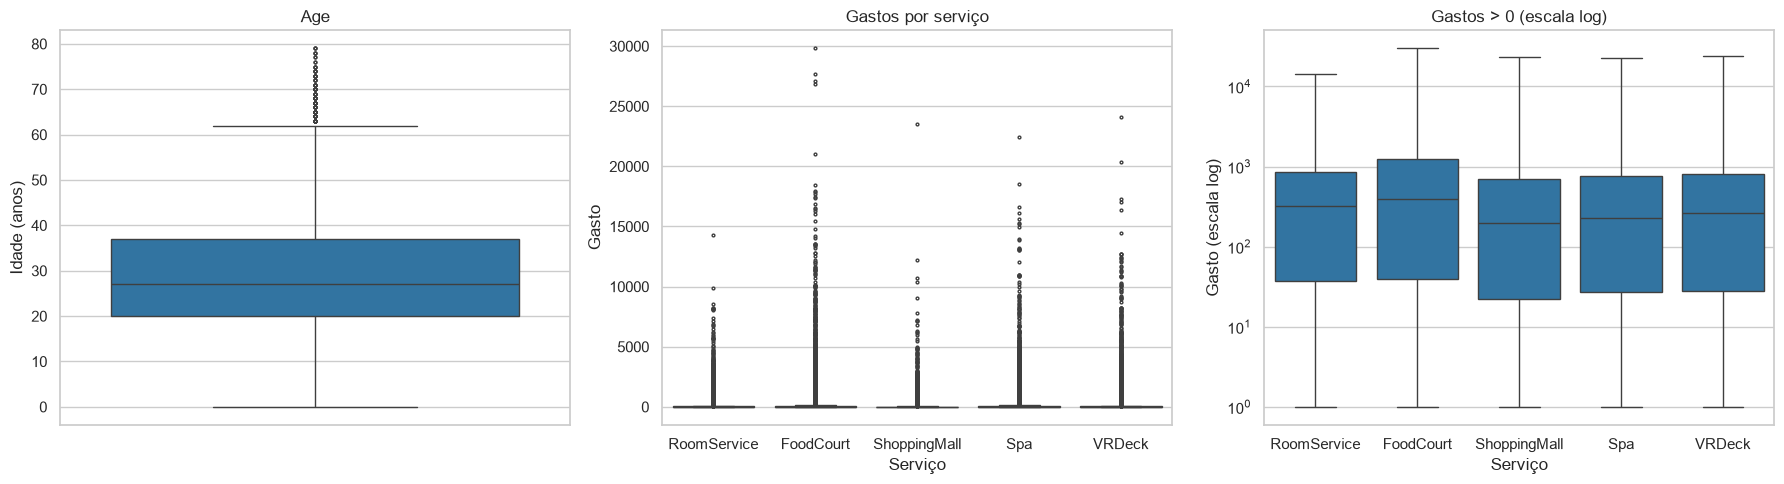

In [22]:
# [IA] Claude – boxplots das quantitativas
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(y=tratado["Age"], ax=axes[0], color="tab:blue", fliersize=2)
axes[0].set_title("Age")
axes[0].set_ylabel("Idade (anos)")
longo = tratado.melt(value_vars=GASTOS, var_name="Serviço", value_name="Gasto")
sns.boxplot(data=longo, x="Serviço", y="Gasto", ax=axes[1], color="tab:blue", fliersize=2)
axes[1].set_title("Gastos por serviço")
axes[1].set_ylabel("Gasto")
sns.boxplot(data=longo[longo["Gasto"] > 0], x="Serviço", y="Gasto", ax=axes[2], color="tab:blue", fliersize=2, log_scale=True)
axes[2].set_title("Gastos > 0 (escala log)")
axes[2].set_ylabel("Gasto (escala log)")
fig.tight_layout()
salvar(fig, "box_outliers.png")
plt.show()

> ✍️ **Análise do grupo:** pelo critério IQR, uns 21% dos gastos seriam outliers, mas isso acontece porque a maioria dos valores é 0 e o limite fica lá embaixo. Não faz muito sentido.

E os gastos altos não parecem erro: não existe valor negativo nem absurdo, e quem gasta muito são justamente os VIPs e os europanos dos decks de cima. Além disso, eles carregam informação, porque só uns 20% dos que gastam muito em `RoomService` e `Spa` foram transportados. As idades altas (até 79 anos) e os grupos de 8 pessoas também são plausíveis.

Então **mantivemos tudo** e só usamos escala log nos gráficos para conseguir enxergar os dados.